# Тюнинг линейной регрессии и ошибки

### О задании

В этом задании вы:
- обучите линейную регрессию, познакомитесь с метриками качества в задачах регресии

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import BaseEstimator
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split

## Часть 1. Линейная регрессия

Для начала загрузим данные и разделим их на обучающую и тестовую выборки в соотношении 7 к 3. Зачем так делать? Когда вы проверяете себя на данных на которых не обучались, вы можете быть уверены что не переобучились. Таким образом если качество на 70% датасета (оубчающей выборке) растёт, а на тестовой выборке падает, то модель начала запоминать датасет (переобучилась), вы что-то делаете не так.


In [3]:
data = load_diabetes()
X_train, X_test, y_train, y_test = train_test_split(data.data, data.target, train_size=0.7, random_state=241)

__Задание 1.__ Обучение линейной регрессии.

**(4 балла)**

Обучите линейную регрессию с $L_1$ (Lasso) и $L_2$ (Ridge) регуляризаторами (используйте параметры по умолчанию). Посмотрите, какое количество коэффициентов близко к 0 (степень близости к 0 определите сами из разумных пределов). Постройте график зависимости числа ненулевых коэффициентов от коэффицента регуляризации (перебирайте значения по логарифмической сетке от $10^{-3}$ до $10^3$).

Спойлер - при большом гиперпараметре регуляризации все параметры стремятся к нулю. На графике это должно быть видно.

Постройте графики коэффициентов регрессии от итерации обучения

In [13]:
from sklearn import datasets, linear_model
from sklearn.linear_model import Ridge, Lasso
import numpy as np

In [14]:
ridge = Ridge().fit(X_train, y_train)
lasso = Lasso().fit(X_train, y_train)

eps = 1.0
print("Ridge: около 0:", np.sum(np.abs(ridge.coef_) < eps))
print("Lasso: около 0:", np.sum(np.abs(lasso.coef_) < eps))
print("Ridge:", ridge.coef_.round(1))
print("Lasso:", lasso.coef_.round(1))

Ridge: около 0: 0
Lasso: около 0: 7
Ridge: [  20.9  -58.   231.3  186.7   33.3   -2.2 -151.   141.4  250.8  123.2]
Lasso: [  0.    0.  274.3  48.6   0.    0.   -0.    0.  424.1   0. ]


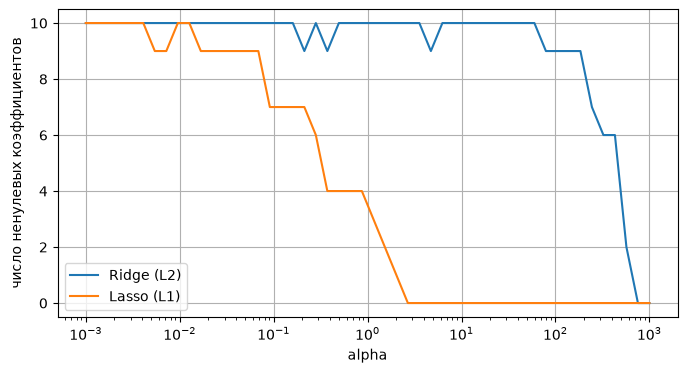

In [15]:
alphas = np.logspace(-3, 3, 50)

nz_ridge, nz_lasso = [], []
for a in alphas:
    nz_ridge.append(np.sum(np.abs(Ridge(alpha=a).fit(X_train, y_train).coef_) > eps))
    nz_lasso.append(np.sum(np.abs(Lasso(alpha=a).fit(X_train, y_train).coef_) > eps))

plt.figure(figsize=(8, 4))
plt.semilogx(alphas, nz_ridge, label="Ridge (L2)")
plt.semilogx(alphas, nz_lasso, label="Lasso (L1)")
plt.xlabel("alpha"); plt.ylabel("число ненулевых коэффициентов")
plt.legend(); plt.grid(); plt.show()

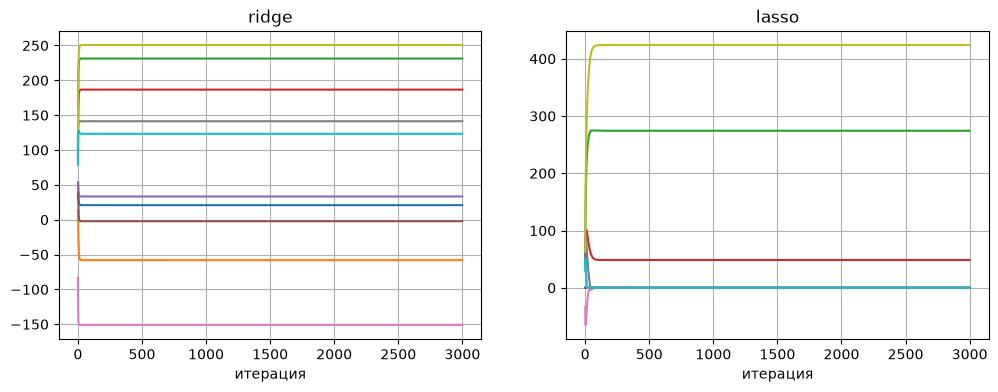

In [16]:
yc = y_train - y_train.mean()
n = len(y_train)

def gd_history(kind, alpha=1.0, lr=50, iters=3000):
    w = np.zeros(X_train.shape[1])
    history = []
    for _ in range(iters):
        grad = X_train.T @ (X_train @ w - yc) / n
        if kind == "ridge":
            w = w - lr * (grad + alpha * w / n)
        else:
            w = w - lr * grad
            w = np.sign(w) * np.maximum(np.abs(w) - lr * alpha, 0)
        history.append(w.copy())
    return np.array(history)

plt.figure(figsize=(12, 4))
for i, kind in enumerate(["ridge", "lasso"]):
    plt.subplot(1, 2, i + 1)
    plt.plot(gd_history(kind))
    plt.title(kind); plt.xlabel("итерация"); plt.grid()
plt.show()

Посчитайте для Ridge-регрессии следующие метрики: $RMSE$, $MAE$, $R^2$.

In [17]:
def get_metrics(y_true, y_pred):
    rmse = np.sqrt(np.mean((y_true - y_pred) ** 2))
    mae = np.mean(np.abs(y_true - y_pred))
    r2 = 1 - np.sum((y_true - y_pred) ** 2) / np.sum((y_true - y_true.mean()) ** 2)
    return rmse, mae, r2

rmse0, mae0, r20 = get_metrics(y_test, ridge.predict(X_test))
print(f"Ridge (alpha=1), тест: RMSE={rmse0:.2f}  MAE={mae0:.2f}  R2={r20:.3f}")

Ridge (alpha=1), тест: RMSE=58.30  MAE=49.60  R2=0.360


Подберите на обучающей выборке для Ridge-регрессии коэффициент регуляризации (перебирайте значения по логарифмической сетке от $10^{-3}$ до $10^3$) для каждой из метрик. Постройте графики зависимости фукнции потерь от коэффициента регуляризации. Посчитайте те же метрики снова. Заметно ли изменилось качество?

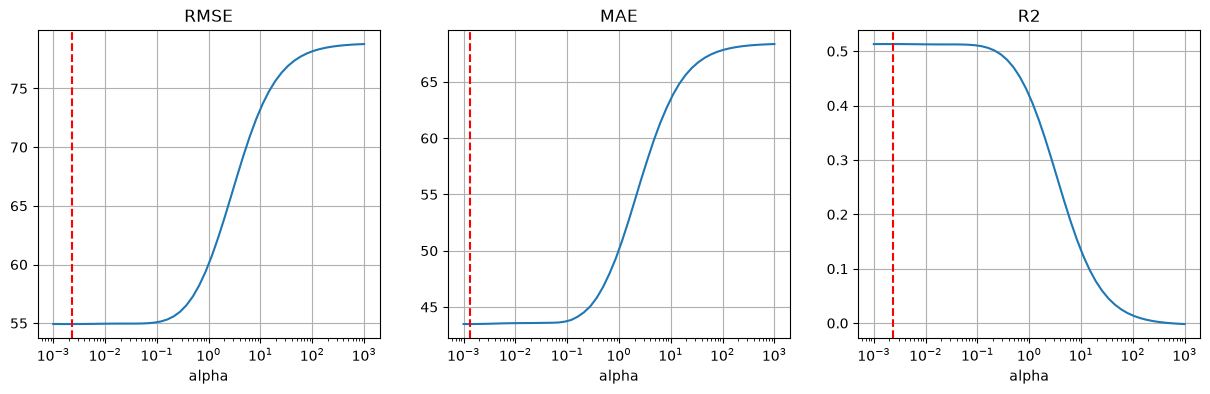

Лучшие alpha: {'RMSE': np.float64(0.002329951810515372), 'MAE': np.float64(0.0013257113655901094), 'R2': np.float64(0.002329951810515372)}
                           RMSE     MAE     R2
alpha=1                  58.304  49.603  0.360
alpha для RMSE = 0.0023  55.812  47.115  0.413
alpha для MAE = 0.0013   55.844  47.144  0.413
alpha для R2 = 0.0023    55.812  47.115  0.413


In [18]:
def cv_predict(model, X, y, k=5):
    idx = np.arange(len(y))
    pred = np.zeros(len(y))
    for fold in np.array_split(idx, k):
        train = np.setdiff1d(idx, fold)
        pred[fold] = model.fit(X[train], y[train]).predict(X[fold])
    return pred

cv = {"RMSE": [], "MAE": [], "R2": []}
for a in alphas:
    m = get_metrics(y_train, cv_predict(Ridge(alpha=a), X_train, y_train))
    for name, value in zip(cv, m):
        cv[name].append(value)

best_alpha = {"RMSE": alphas[np.argmin(cv["RMSE"])],
              "MAE": alphas[np.argmin(cv["MAE"])],
              "R2": alphas[np.argmax(cv["R2"])]}

plt.figure(figsize=(15, 4))
for i, name in enumerate(cv):
    plt.subplot(1, 3, i + 1)
    plt.semilogx(alphas, cv[name])
    plt.axvline(best_alpha[name], color="r", ls="--")
    plt.title(name); plt.xlabel("alpha"); plt.grid()
plt.show()

print("Лучшие alpha:", best_alpha)
rows = {"alpha=1": get_metrics(y_test, ridge.predict(X_test))}
for name, a in best_alpha.items():
    model = Ridge(alpha=a).fit(X_train, y_train)
    rows[f"alpha для {name} = {a:.4f}"] = get_metrics(y_test, model.predict(X_test))
print(pd.DataFrame(rows, index=["RMSE", "MAE", "R2"]).T.round(3))

__Задание 2.__ Поиск объектов-выбросов

**(4 балла)**

Как известно, MSE сильно штрафует за большие ошибки на объектах-выбросах. Посчитайте ошибки и посмотрите на их распределение (plt.hist). Что вы видите?

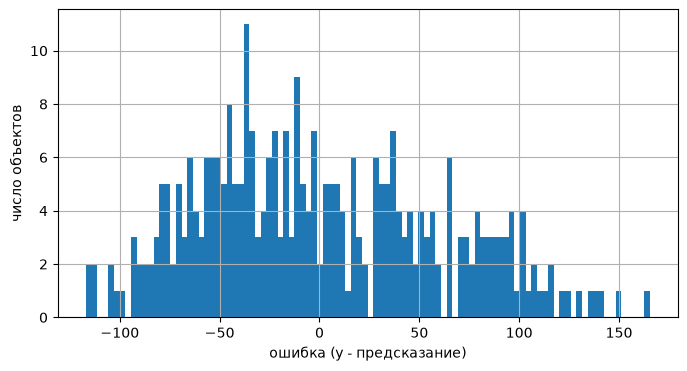

std: 60.0  max |ошибки|: 165.3


In [29]:
errors = y_train - cv_predict(Ridge(), X_train, y_train)

plt.figure(figsize=(8, 4))
plt.hist(errors, bins=100)
plt.xlabel("ошибка (y - предсказание)"); plt.ylabel("число объектов")
plt.grid(); plt.show()
print("std:", errors.std().round(1), " max |ошибки|:", np.abs(errors).max().round(1))

Попробуйте удалить объекты-выбросы из обучающей выборки (что считать или не считать выбросами на ваше усмотрение). Обучите модель заново и посмотрите на качество на отложенной выборке (учитывайте, что там тоже могут быть выбросы, с которыми вы ничего не можете сделать). Стало ли лучше? Чем вы можете объяснить это?

In [11]:
mask = np.abs(errors) < 2 * errors.std()
print("Оставили объектов:", mask.sum(), "из", len(mask))

ridge_clean = Ridge().fit(X_train[mask], y_train[mask])
before = get_metrics(y_test, ridge.predict(X_test))
after = get_metrics(y_test, ridge_clean.predict(X_test))
print(pd.DataFrame([before, after], index=["с выбросами", "без выбросов"],
                   columns=["RMSE", "MAE", "R2"]).round(3))

Оставили объектов: 301 из 309
                RMSE     MAE     R2
с выбросами   58.304  49.603  0.360
без выбросов  59.508  50.512  0.333


__Задание 3.__ Отчёт

**(2 балла)**

In [20]:
report = pd.DataFrame(
    [get_metrics(y_test, ridge.predict(X_test))] +
    [get_metrics(y_test, Ridge(alpha=best_alpha[k]).fit(X_train, y_train).predict(X_test))
     for k in ["RMSE", "MAE", "R2"]] +
    [after],
    index=["Ridge, alpha=1", "Ridge, alpha по RMSE", "Ridge, alpha по MAE",
           "Ridge, alpha по R2", "Ridge без выбросов"],
    columns=["RMSE", "MAE", "R2"]).round(3)
report

,RMSE,MAE,R2
"Ridge, alpha=1",58.304,49.603,0.360
"Ridge, alpha по RMSE",55.812,47.115,0.413
"Ridge, alpha по MAE",55.844,47.144,0.413
"Ridge, alpha по R2",55.812,47.115,0.413
Ridge без выбросов,59.508,50.512,0.333
